<a href="https://colab.research.google.com/github/e-j223/IS4487/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [1]:
# Add code here 🔧
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import PercentFormatter
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

base_url = (
    "https://raw.githubusercontent.com/Stan-Pugsley/"
    "is_4487_base/refs/heads/main/DataSets/"
)

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [2]:
# Add code here 🔧
df = pd.read_csv(base_url + "adviseinvest_historical_data.csv")

print("Dataset shape:", df.shape)
display(df.head())
display(df.describe(include='all').T)

print("Missing values:")
print(df.isna().sum().loc[lambda counts: counts > 0])
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated customer IDs:", df['customer_id'].duplicated().sum())
print("Female codes:", sorted(df['female'].unique()))

unusual = (
    df['income'].lt(0)
    | df['age'].gt(100)
    | df['num_accts'].gt(8)
)
display(df.loc[unusual, ['customer_id', 'income', 'age', 'num_accts']])

Dataset shape: (29504, 15)


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,29504.0,NaN,NaN,NaN,14850.475563,8517.25431,99.0,7474.75,14850.5,22226.25,29602.0
answered,29504.0,NaN,NaN,NaN,0.546638,0.497829,0.0,0.0,1.0,1.0,1.0
income,29504.0,NaN,NaN,NaN,33766.893303,29379.20271,-65600.0,13550.0,23310.0,41690.0,159450.0
female,29504,3,0,27903,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,29504.0,NaN,NaN,NaN,34.773454,11.369865,19.0,26.0,32.0,40.0,132.0
job,29504.0,NaN,NaN,NaN,1.915401,0.658183,0.0,2.0,2.0,2.0,3.0
num_dependents,29504.0,NaN,NaN,NaN,1.140998,0.348025,1.0,1.0,1.0,1.0,2.0
rent,29504.0,NaN,NaN,NaN,0.210412,0.407608,0.0,0.0,0.0,0.0,1.0
own_res,29504.0,NaN,NaN,NaN,0.681128,0.466047,0.0,0.0,1.0,1.0,1.0
new_car,29502.0,NaN,NaN,NaN,0.240797,0.427575,0.0,0.0,0.0,0.0,1.0


Missing values:
new_car    2
dtype: int64
Exact duplicate rows: 3
Repeated customer IDs: 3
Female codes: ['0', '1', 'M']


,customer_id,income,age,num_accts
0,10098,-65600,24,3
1153,132,9310,132,1
13376,198,-15430,33,2
24415,15098,30590,61,3345


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. 1.1. A few values stood out right away. Two customers had negative incomes, one was listed as 132 years old, and one had 3,345 accounts. The 'female' column also had an 'M' mixed in with the 0 and 1 codes. I found two missing values in 'new_car' and three exact duplicate rows.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [3]:
# Add code here 🔧
def clean_customers(data):
    data = data.drop_duplicates().copy()
    data['female'] = data['female'].replace('M', '0')

    valid = (
        data['income'].ge(0)
        & data['age'].between(18, 100)
        & data['num_accts'].between(0, 8)
    )
    data = data.loc[valid].dropna(subset=['new_car'])
    return data.drop(columns=['customer_id', 'product'], errors='ignore')


df_clean = clean_customers(df)
print("Cleaned shape:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))
print("Missing values remaining:", df_clean.isna().sum().sum())

Cleaned shape: (29495, 13)
Rows removed: 9
Missing values remaining: 0


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 I removed three duplicate rows, two negative incomes, the age of 132, and the account count of 3,345. I kept the customer with eight accounts because that count is plausible. I also changed M to 0 to match the data dictionary’s male code. Only two rows were missing new_car, so I dropped those rows instead of guessing their values.

2.6 I removed customer_id because it’s just an identifier. I removed product because we only know what someone bought after the call. Using it would give the model information it wouldn’t have when making a prediction.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [4]:
# Add code here 🔧
def standardize_customers(data):
    data = data.copy()
    if 'answered' in data:
        data['answered'] = data['answered'].astype(bool)

    integer_types = {
        column: 'int64' for column in data.columns if column != 'answered'
    }
    return data.astype(integer_types)


df_clean = standardize_customers(df_clean)
print(df_clean.dtypes)

answered           bool
income            int64
female            int64
age               int64
job               int64
num_dependents    int64
rent              int64
own_res           int64
new_car           int64
chk_acct          int64
sav_acct          int64
num_accts         int64
mobile            int64
dtype: object


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [5]:
# Add code here 🔧
category_cols = ['job', 'chk_acct', 'sav_acct']

df_clean[category_cols] = df_clean[category_cols].astype('category')
print(df_clean[category_cols].dtypes)

job         category
chk_acct    category
sav_acct    category
dtype: object


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



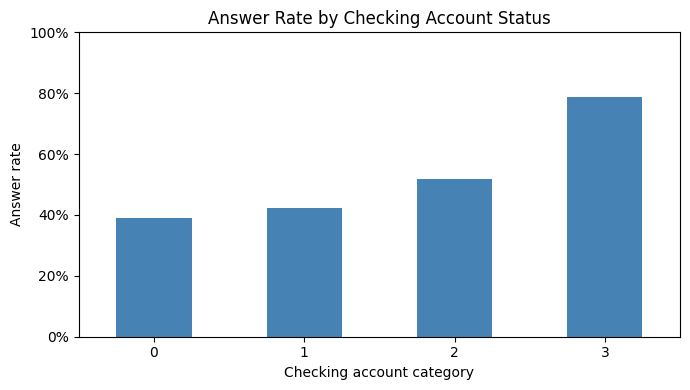

In [6]:
# Chart 3.1 🔧
rates = df_clean.groupby('chk_acct', observed=True)['answered'].mean()

fig, ax = plt.subplots(figsize=(7, 4))
rates.plot.bar(ax=ax, color='steelblue', rot=0)
ax.set(
    title='Answer Rate by Checking Account Status',
    xlabel='Checking account category',
    ylabel='Answer rate',
    ylim=(0, 1)
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()


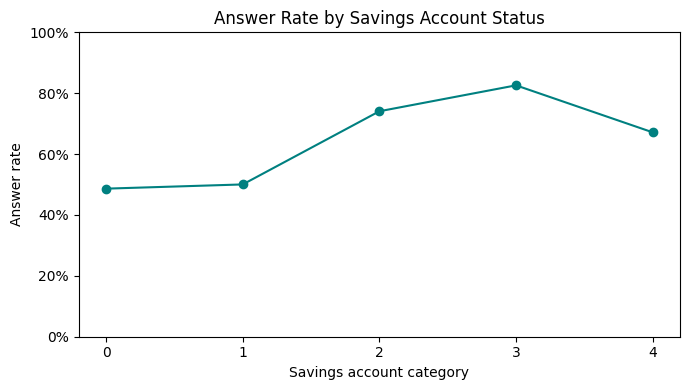

In [7]:
# Chart 3.2 🔧
rates = df_clean.groupby('sav_acct', observed=True)['answered'].mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rates.index, rates.values, marker='o', color='teal')
ax.set(
    title='Answer Rate by Savings Account Status',
    xlabel='Savings account category',
    ylabel='Answer rate',
    xticks=rates.index,
    ylim=(0, 1)
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

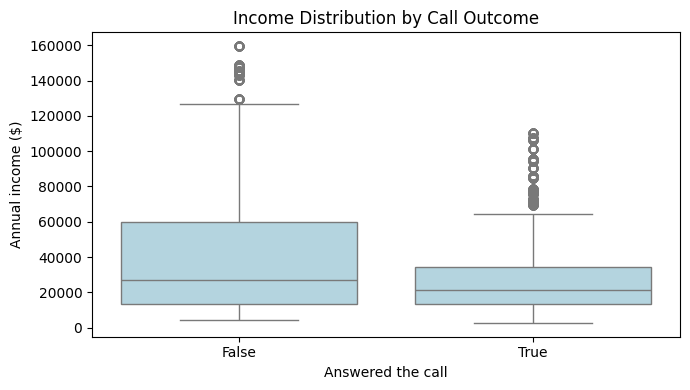

In [8]:
# Chart 3.3 🔧
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df_clean, x='answered', y='income', ax=ax, color='lightblue')
ax.set(
    title='Income Distribution by Call Outcome',
    xlabel='Answered the call',
    ylabel='Annual income ($)'
)
plt.tight_layout()
plt.show()

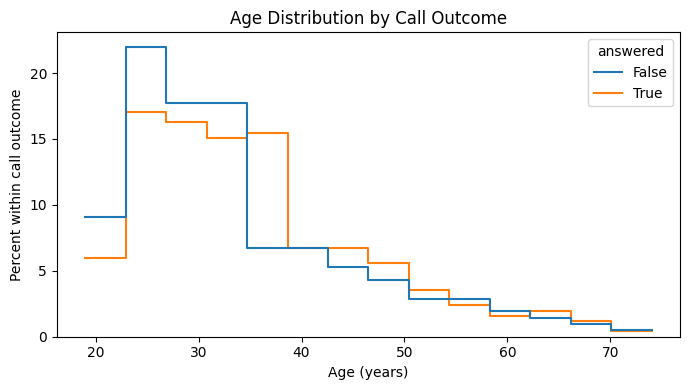

In [9]:
# Chart 3.4 🔧
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(
    data=df_clean, x='age', hue='answered', bins=14,
    stat='percent', common_norm=False, element='step', fill=False, ax=ax
)
ax.set(
    title='Age Distribution by Call Outcome',
    xlabel='Age (years)',
    ylabel='Percent within call outcome'
)
plt.tight_layout()
plt.show()

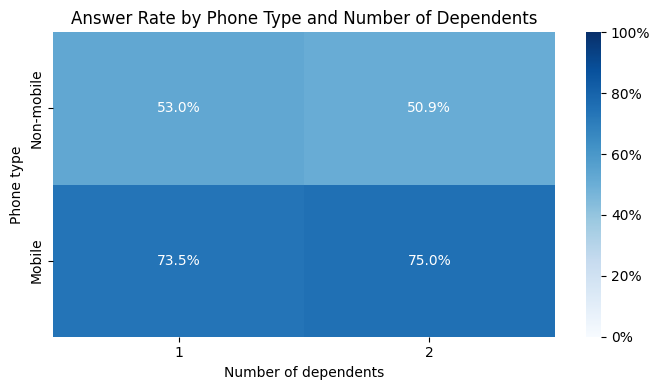

In [10]:
# Chart 3.5 🔧
rates = df_clean.pivot_table(
    index='mobile', columns='num_dependents',
    values='answered', aggfunc='mean'
).rename(index={0: 'Non-mobile', 1: 'Mobile'})

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(
    rates, annot=True, fmt='.1%', vmin=0, vmax=1, cmap='Blues',
    cbar_kws={'format': PercentFormatter(1)}, ax=ax
)
ax.set(
    title='Answer Rate by Phone Type and Number of Dependents',
    xlabel='Number of dependents',
    ylabel='Phone type'
)
plt.tight_layout()
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Checking and savings account status stood out the most. For example, about 39% of customers with no checking account answered, compared with about 79% in checking category 3. Customers who gave a mobile number were also more likely to answer.

3.7. The number of dependents looked weak on its own. The answer rate was about 55% for one dependent and 54% for two. I kept it for the tree because it could still help when combined with another variable.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [12]:
# Add code here 🔧
base_probability = df_clean['answered'].mean()
print(f"Baseline probability of answering: {base_probability:.2%}")

Baseline probability of answering: 54.67%


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [13]:
# Add code here 🔧
X = df_clean.drop(columns='answered')
y = df_clean['answered']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (23596, 12)
Testing shape: (5899, 12)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

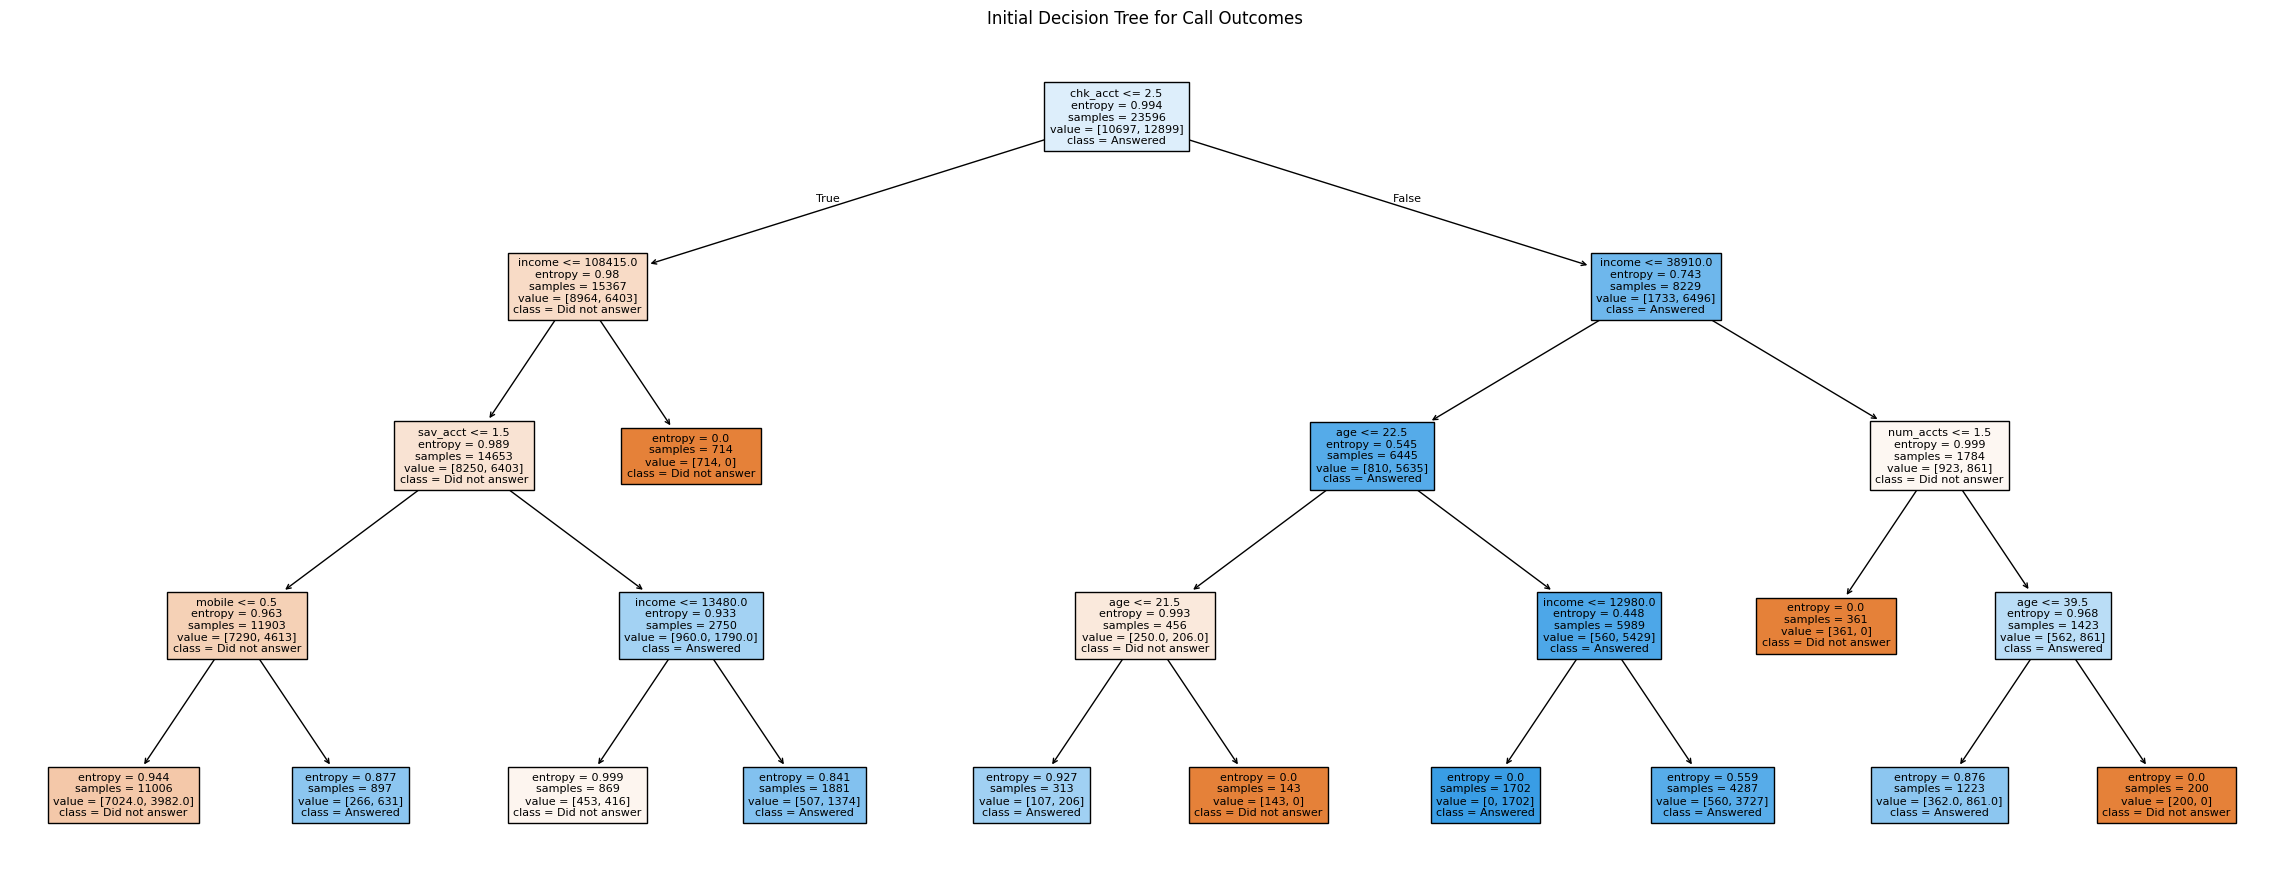

In [14]:
# Add code here 🔧
tree = DecisionTreeClassifier(
    criterion='entropy', max_depth=4, random_state=42
)
tree.fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(23, 9))
plot_tree(
    tree,
    feature_names=X.columns.tolist(),
    class_names=['Did not answer', 'Answered'],
    filled=True,
    fontsize=8,
    ax=ax
)
ax.set_title('Initial Decision Tree for Call Outcomes')
plt.tight_layout()
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [15]:
# Add code here 🔧
y_pred = tree.predict(X_test)
initial_accuracy = accuracy_score(y_test, y_pred)

print(f"Initial tree test accuracy: {initial_accuracy:.2%}")
print(f"Improvement over baseline: {(initial_accuracy - base_probability) * 100:.2f} points")

Initial tree test accuracy: 73.83%
Improvement over baseline: 19.16 points


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The tree got 73.83% of the test predictions right, compared with a baseline of 54.67%. That’s an improvement of 19.16 percent.

2. That’s a meaningful increase in accuracy, but the business still needs to look at the kinds of mistakes the tree makes. Skipping a customer who would have answered can cost more than placing a call that goes unanswered.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [16]:
# Add code here 🔧
cm = confusion_matrix(y_test, y_pred, labels=[False, True])
tn, fp, fn, tp = cm.ravel()
print(cm)

[[2236  438]
 [1106 2119]]


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

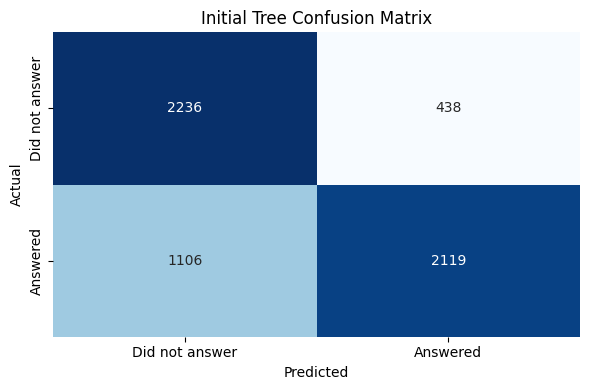

In [17]:
# Add code here 🔧
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Did not answer', 'Answered'],
    yticklabels=['Did not answer', 'Answered'],
    ax=ax
)
ax.set(title='Initial Tree Confusion Matrix', xlabel='Predicted', ylabel='Actual')
plt.tight_layout()
plt.show()

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [19]:
# Add code here 🔧
model_profit = tp * 75 - fp * 25
print(f"Profit using the initial model: ${model_profit:,.0f}")

Profit using the initial model: $147,975


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [21]:
# Add code here 🔧
answered_calls = y_test.sum()
unanswered_calls = len(y_test) - answered_calls
default_profit = answered_calls * 75 - unanswered_calls * 25

print(f"Profit from calling everyone: ${default_profit:,.0f}")
print(f"Initial model minus default: ${model_profit - default_profit:,.0f}")

Profit from calling everyone: $175,025
Initial model minus default: $-27,050


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. Calling everyone earned 175,025 dollars under the assignment’s assumptions, compared with 147,975 using the initial tree. That’s 27,050 more than the initial tree earned.

2. I’d consider that a meaningful difference. The tree avoided some calls that would have gone unanswered, but it also skipped 1,106 customers who would have answered. The savings on unanswered calls didn’t make up for those missed opportunities.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [24]:
# Add code here 🔧
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

validation_scores = {}

for depth in [4, 6, 8, 10]:
    candidate = DecisionTreeClassifier(
        criterion='entropy', max_depth=depth, random_state=42
    )
    candidate.fit(X_fit, y_fit)
    validation_scores[depth] = candidate.score(X_val, y_val)
    print(f"Depth {depth}: {validation_scores[depth]:.2%} validation accuracy")

best_depth = max(validation_scores, key=validation_scores.get)
tree_tuned = DecisionTreeClassifier(
    criterion='entropy', max_depth=best_depth, random_state=42
)
tree_tuned.fit(X_train, y_train)

y_pred_tuned = tree_tuned.predict(X_test)
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

_, tuned_fp, _, tuned_tp = confusion_matrix(
    y_test, y_pred_tuned, labels=[False, True]
).ravel()
tuned_profit = tuned_tp * 75 - tuned_fp * 25

print(f"\nBest depth: {best_depth}")
print(f"Tuned tree test accuracy: {tuned_accuracy:.2%}")
print(f"Tuned tree profit: ${tuned_profit:,.0f}")
print(f"Tuned profit minus default: ${tuned_profit - default_profit:,.0f}")

Depth 4: 73.55% validation accuracy
Depth 6: 79.34% validation accuracy
Depth 8: 83.81% validation accuracy
Depth 10: 86.17% validation accuracy

Best depth: 10
Tuned tree test accuracy: 84.45%
Tuned tree profit: $179,550
Tuned profit minus default: $4,525


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

In [25]:
# Add code here 🔧
new_customers = pd.read_csv(base_url + "adviseinvest_new_customer_data.csv")

new_clean = standardize_customers(clean_customers(new_customers))
new_clean[category_cols] = new_clean[category_cols].astype('category')
new_X = new_clean[X.columns]

predictions = new_customers.loc[new_X.index, ['customer_id']].copy()
predictions['predicted_answered'] = tree_tuned.predict(new_X)

display(predictions.head())
print("Customers scored:", len(predictions))
print("Predicted to answer:", predictions['predicted_answered'].sum())
print("Predicted not to answer:", (~predictions['predicted_answered']).sum())

,customer_id,predicted_answered
0,H1597,False
1,P1446,False
2,E1492,False
3,W5143,False
4,W4927,False


Customers scored: 1000
Predicted to answer: 449
Predicted not to answer: 551


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 The initial tree lowered simulated profit, but the tuned tree earned 179,550 dollars compared with 175,025 from calling everyone. That’s a gain of 4,525, or about 2.6%, under the assignment’s assumptions.

6.2 I’d use the predictions to spread customers who are likely to answer across the four reps so one rep doesn’t end up with most of the live calls. I’d test that approach on a fresh set of scheduled calls first. The same customer profiles show up in both the training and test sets, so the accuracy we got here may be higher than what we’d see in practice.|

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"